In [6]:
from pathlib import Path
import pandas as pd
import requests
import zipfile
from io import BytesIO

DATA_DIR = Path("/content/beijing_data")
OUTPUT_PATH = DATA_DIR / "processed/aotizhongxin_baseline.csv"

if not OUTPUT_PATH.exists():
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00501/PRSA2017_Data_20130301-20170228.zip"

    response = requests.get(url)
    response.raise_for_status()

    with zipfile.ZipFile(BytesIO(response.content)) as z:
        z.extractall(DATA_DIR)

    file_path = next(DATA_DIR.rglob("*Aotizhongxin*.csv"))
    df = pd.read_csv(file_path)

    OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUTPUT_PATH, index=False)

df = pd.read_csv(OUTPUT_PATH)

print("Dataset loaded successfully:", df.shape)
display(df.head())

Dataset loaded successfully: (35064, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")
plt.rcParams["figure.figsize"] = (12, 5)

In [8]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("/content/beijing_data/processed/aotizhongxin_baseline.csv")

df = pd.read_csv(DATA_PATH)

df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])

df = df.set_index("datetime")

print("Dataset loaded successfully:", df.shape)
display(df.head())

Dataset loaded successfully: (35064, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
datetime,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
2013-03-01 01:00:00,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2013-03-01 02:00:00,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
2013-03-01 04:00:00,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [9]:
# Shape and time range
print("Shape:", df.shape)
print("Start date:", df.index.min())
print("End date:", df.index.max())

Shape: (35064, 18)
Start date: 2013-03-01 00:00:00
End date: 2017-02-28 23:00:00


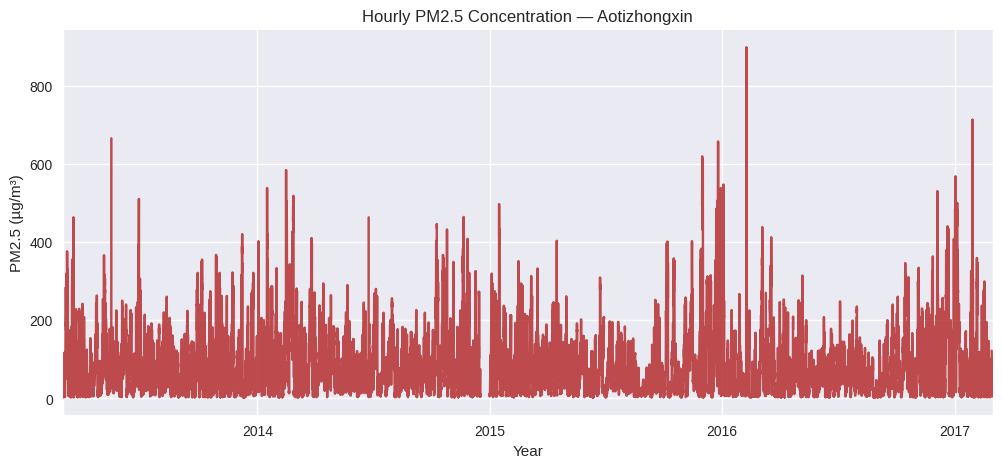

In [10]:
# Tie series plot for PM 2.5
df["PM2.5"].plot(color="firebrick", alpha=0.8)
plt.title("Hourly PM2.5 Concentration — Aotizhongxin")
plt.ylabel("PM2.5 (µg/m³)")
plt.xlabel("Year")
plt.show()

/tmp/ipykernel_1309/2654253696.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_pm25 = df["PM2.5"].resample("M").mean()


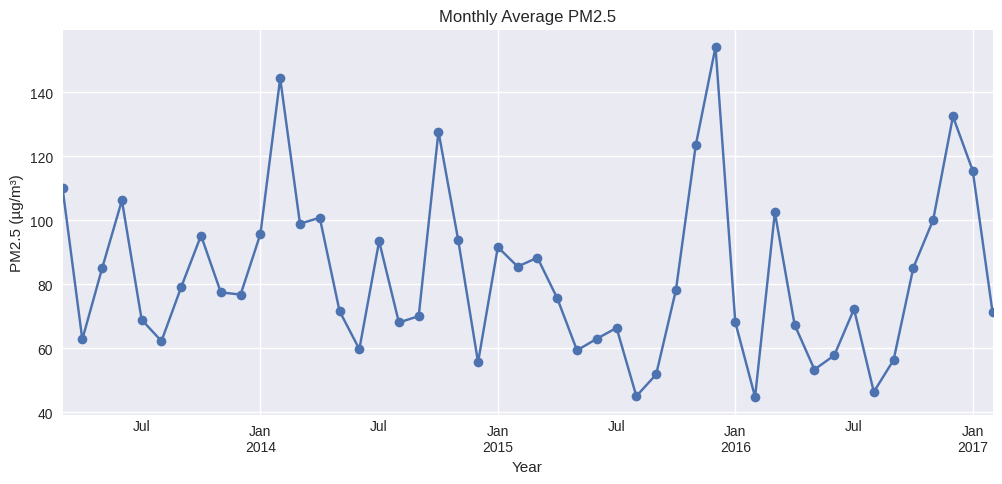

In [11]:
# Monthly averages
monthly_pm25 = df["PM2.5"].resample("M").mean()

monthly_pm25.plot(marker="o")
plt.title("Monthly Average PM2.5")
plt.ylabel("PM2.5 (µg/m³)")
plt.xlabel("Year")
plt.show()

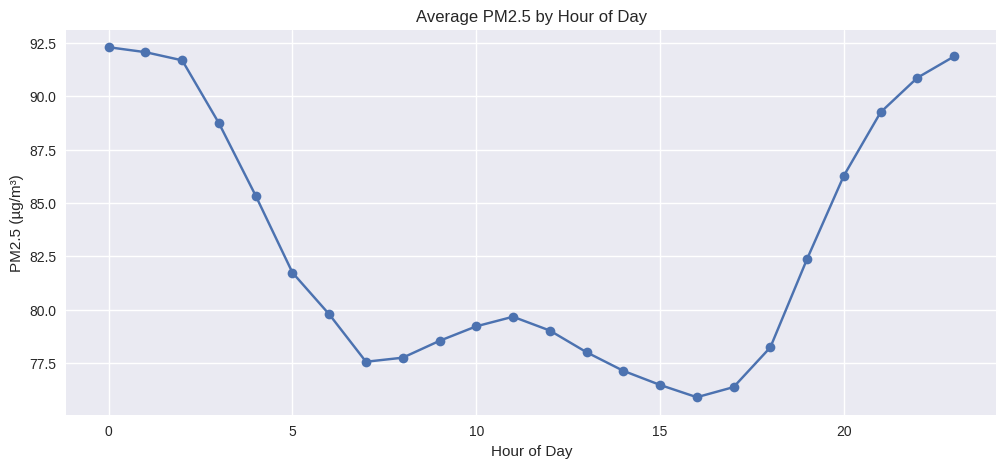

In [12]:
# Hour of day pattern
hourly_pattern = df.groupby(df.index.hour)["PM2.5"].mean()

hourly_pattern.plot(marker="o")
plt.title("Average PM2.5 by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

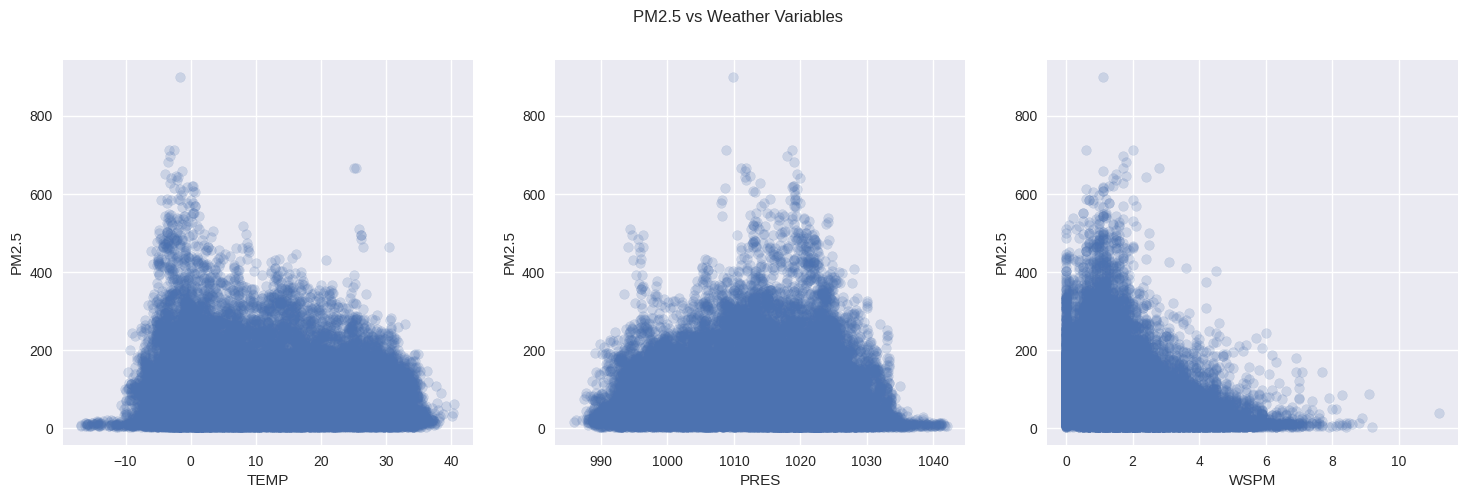

In [13]:
# Scatter plot for weather vs PM2.5
weather_vars = ["TEMP", "PRES", "WSPM"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, var in zip(axes, weather_vars):
    ax.scatter(df[var], df["PM2.5"], alpha=0.2)
    ax.set_xlabel(var)
    ax.set_ylabel("PM2.5")

plt.suptitle("PM2.5 vs Weather Variables")
plt.show()

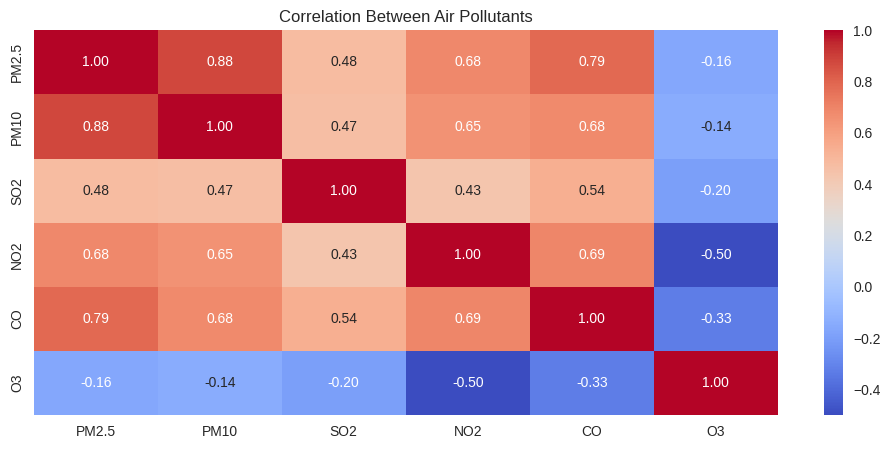

In [14]:
# Correlation heatmap
pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

corr = df[pollutants].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Air Pollutants")
plt.show()

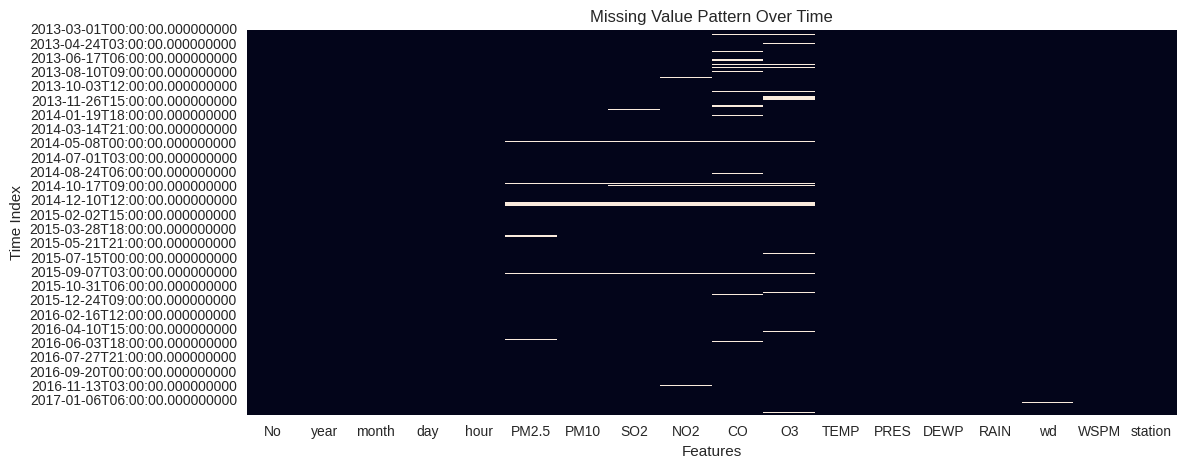

In [15]:
# Missing values heatmap
sns.heatmap(df.isna(), cbar=False)
plt.title("Missing Value Pattern Over Time")
plt.xlabel("Features")
plt.ylabel("Time Index")
plt.show()